# EMQA_L6_spreads

**Daily price spread: monthly mean of the daily difference between the 2 most expensive and the 2 cheapest hours of the day-ahead price (hourly prices, 15-min averaged to the hour) in Romania, Bulgaria, Hungary and Germany-Luxembourg, 2019 to 2026-10-31. Prints the mean daily spread of 2026 by zone.**

Energy Markets Quantitative Analysis (EMQA), Lecture 6 · Daniel Traian Pele, Bucharest University of Economic Studies

[Open in Colab](https://colab.research.google.com/github/danpele/EMQA/blob/main/Quantlets/L6/EMQA_L6_spreads/EMQA_L6_spreads.ipynb)

In [1]:
import os
# course data: the local copy of the repository if there is one, else the public repository on GitHub
_LOCAL = os.path.join('..', '..', '..', 'data', 'clean')
DATA = _LOCAL + os.sep if os.path.isdir(_LOCAL) else 'https://raw.githubusercontent.com/danpele/EMQA/main/data/clean/'
REPO = os.path.join('..', '..', '..') + os.sep if os.path.isdir(_LOCAL) else 'https://raw.githubusercontent.com/danpele/EMQA/main/'

## Setup: chart style and data period

In [2]:
import json
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings('ignore')

# course chart style: transparent background, no grid, legend at the bottom outside the axes, fixed colour per zone
PAL = {'RO': '#2a78d6', 'DE_LU': '#eb6834', 'HU': '#1baf7a', 'BG': '#eda100',
       'c5': '#e87ba4', 'c6': '#008300', 'c7': '#6250d6', 'c8': '#e34948'}
ZONE_LS = {'RO': '-', 'BG': '--', 'HU': '-.', 'DE_LU': ':'}
ZN = {'RO': 'Romania', 'BG': 'Bulgaria', 'HU': 'Hungary', 'DE_LU': 'Germany-Lux.'}
INK = '#222222'
plt.rcParams.update({
    'figure.facecolor': 'none', 'axes.facecolor': 'none', 'savefig.transparent': True,
    'axes.grid': False, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.edgecolor': INK, 'axes.labelcolor': INK, 'xtick.color': INK, 'ytick.color': INK,
    'text.color': INK, 'font.size': 11, 'axes.titlesize': 11.5, 'axes.labelsize': 11,
    'legend.fontsize': 10.5, 'legend.frameon': False, 'lines.linewidth': 1.4, 'font.family': 'DejaVu Sans'})


def legend_bottom(fig, ncol=4):
    """One legend for the whole figure, centred under the axes, outside the plotting area."""
    handles, labels = [], []
    for ax in fig.axes:
        for h, l in zip(*ax.get_legend_handles_labels()):
            if l not in labels:
                handles.append(h)
                labels.append(l)
    fig.legend(handles, labels, loc='lower center', ncol=ncol, bbox_to_anchor=(0.5, 0.0), frameon=False,
               handlelength=2.0, columnspacing=1.2)


def fl(x, k=4):
    """Rounding used for the numbers of the slides."""
    return None if x is None or np.isnan(float(x)) else round(float(x), k)


def show_numbers(d):
    for k, v in d.items():
        print(f'{k:<34} {v}')

Spread of day d: mean of the 2 most expensive hours minus mean of the 2 cheapest hours (duration-weighted, complete delivery days only); monthly means of the daily values.

In [3]:
TZ = 'Europe/Brussels'                     # delivery days in CET/CEST
END = pd.Timestamp('2026-10-31')               # cut-off of Lecture 6 = last complete month of the data
END_X = (END + pd.Timedelta(days=1)).tz_localize(TZ)
Y = END.year
YEARS = list(range(2019, Y + 1))
MON_EN = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']
YTD = f'* {Y} = Jan-{MON_EN[END.month - 1]}'
LTM0 = pd.Timestamp('2025-11-01').tz_localize(TZ)    # first day of the last 12 months
MTU15 = pd.Timestamp('2025-10-01').tz_localize(TZ)   # 15-min market time unit from 1 Oct 2025

In [4]:
# day-ahead prices, EUR/MWh: hourly to 30 Sep 2025, 15-min from 1 Oct 2025 (SDAC); index in CET/CEST
PX = pd.read_csv(DATA + 'power_da_prices_native_utc.csv', parse_dates=['timestamp_utc']).set_index('timestamp_utc')
PX.index = PX.index.tz_convert(TZ)
PX['dur'] = PX['mtu_minutes'] / 60.0          # interval length in hours
PX = PX[PX.index < END_X]
LOC_YEAR = PX.index.year
print('prices:', PX.index.min(), 'to', PX.index.max(), '|', (PX['mtu_minutes'] == 15).sum(), '15-min intervals')

prices: 2015-01-01 01:00:00+01:00 to 2026-10-31 23:45:00+01:00 | 38020 15-min intervals


In [5]:
def hfloor(idx):
    """Start of the clock hour, computed in UTC (no ambiguity on the autumn DST day)."""
    return idx.tz_convert('UTC').floor('1h').tz_convert(TZ)


def day_groups(zone, start=None, end=None, hourly=False):
    """Prices per CET delivery day (complete days only: 23/24/25 hours or 92/96/100 quarter-hours)."""
    s = PX[[zone, 'dur']]
    if start is not None:
        s = s[s.index >= start]
    if end is not None:
        s = s[s.index < end]
    if hourly:
        s = s.groupby(hfloor(s.index)).agg({zone: 'mean', 'dur': 'sum'})
    out = {}
    for dd, g in s.groupby(s.index.tz_localize(None).normalize()):
        if g[zone].notna().all() and abs(g['dur'].sum() - round(g['dur'].sum())) < 1e-9 and round(g['dur'].sum()) in (23, 24, 25):
            out[dd] = (g[zone].values.astype(float), g['dur'].values.astype(float))
    return out

In [6]:
def tbk(p, dur, k):
    """Top-k minus bottom-k hours spread of one day (duration-weighted means of the k most expensive / cheapest hours)."""
    o = np.argsort(p)

    def avg(idx):
        acc, tot = 0.0, 0.0
        for i_, wi in zip(idx, dur[idx]):
            take = min(wi, k - tot)
            if take <= 0:
                break
            acc += p[i_] * take
            tot += take
        return acc / tot
    return avg(o[::-1]) - avg(o)


ZONES = ['RO', 'BG', 'HU', 'DE_LU']
SPR = {}
for z in ZONES:
    dg = day_groups(z, start=pd.Timestamp('2019-01-01').tz_localize(TZ), hourly=True)
    SPR[z] = pd.Series({dd: tbk(p, w, 2) for dd, (p, w) in dg.items()})
SPRM = {z: SPR[z].groupby(SPR[z].index.to_period('M')).mean() for z in ZONES}
show_numbers({f'spread.{z}.{Y}': fl(SPR[z][SPR[z].index.year == Y].mean(), 1) for z in ZONES})

spread.RO.2026                     173.9
spread.BG.2026                     149.8
spread.HU.2026                     186.8
spread.DE_LU.2026                  151.5


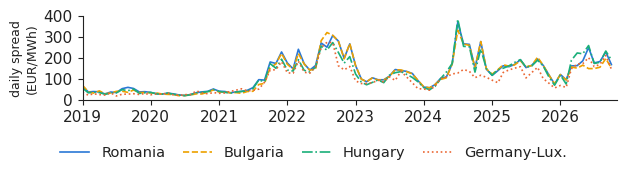

In [7]:
import matplotlib.dates as mdates

fig, ax = plt.subplots(figsize=(6.4, 1.8))
for z in ZONES:
    s = SPRM[z]
    ax.plot(s.index.to_timestamp(), s.values, color=PAL[z], ls=ZONE_LS[z], lw=1.2, label=ZN[z])
ax.set_ylabel('daily spread\n(EUR/MWh)', fontsize=9)
ax.set_ylim(0, 400)
ax.set_yticks([0, 100, 200, 300, 400])
ax.xaxis.set_major_locator(mdates.YearLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
ax.set_xlim(pd.Timestamp('2019-01-01'), END)
legend_bottom(fig, ncol=4)
fig.canvas.draw()
legend_h = max([lg.get_window_extent().height for lg in fig.legends] or [0.0]) / fig.bbox.height
fig.tight_layout(rect=(0, legend_h + 0.035, 1, 1))
plt.savefig('spreads.png', dpi=150, bbox_inches='tight', transparent=True)
plt.show()